# Evaluating Emulator performance in Shadow mode within WOMBATfull*_hy

In [7]:
import xarray as xr
import pandas as pd
import glob
from dask import delayed, compute
import dask
import os
import matplotlib.pyplot as plt
import numpy as np

PATH_DATA =  '/../../../g/data/jk72/ao2582/PyTorch/shadow_data/run_shadow_iaf_1/output/'
#path_data =  '/../../../g/data/jk72/ao2582/PyTorch/shadow_data/run_shadow_003/output/'
#path_data = '/scratch/zn44/ao2582/access-om3/archive/mid_shadow_iaf_todz/output000/'

FILES = glob.glob(PATH_DATA + "*.nc")
#print(files)

PARAMS = ['thetao', 'mes', 'phy', 'zoo','det', 'dia', 'bdet', 'bac1','fe','o2', 'det_vmove', 'mlotst', 'detremi','bdetremi','poc1remi','poc1remi_nn']

# --- Optimized file loading function ---
def open_om3_variable(path_exp, varname):
    pattern = f"{path_exp}/access-om3.mom6.*d.{varname}.1day.mean.*.nc"
    files = sorted(glob.glob(pattern))
   # print(files)
    if not files:
        raise FileNotFoundError(f"No files found for variable {varname}")

    ds = xr.open_mfdataset(
        files,
        combine="nested",
        concat_dim="time",
        data_vars="minimal",
        coords="minimal",
        compat="override",
        decode_times=False,
        #chunks={"time": 365},  # Enable chunking per year
        #parallel=True  # Faster with many files
        )
    return ds


In [8]:
# Load all variables and merge
ds_list = []
for var in params:
    try:
        ds_var = open_om3_variable(path_data, var)
        ds_list.append(ds_var)
        ds_var.close()
    except FileNotFoundError:
        print(f" Missing variable {var}")


# Merge variables
ds = xr.merge(ds_list, compat="override", join="override")
# Fix time encoding
ds = ds.assign_coords(time=ds.time)  # Ensure time is coordinate
ds.time.attrs["units"] = "days since 0001-01-01 00:00:00"
ds.time.attrs["calendar"] = "julian"
ds_om3 = xr.decode_cf(ds, decode_timedelta=False).compute().mean(dim=['xh','yh'])


    
print('-- done')

-- done


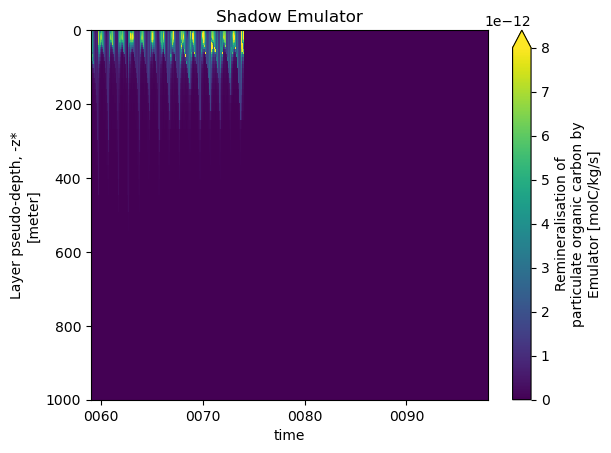

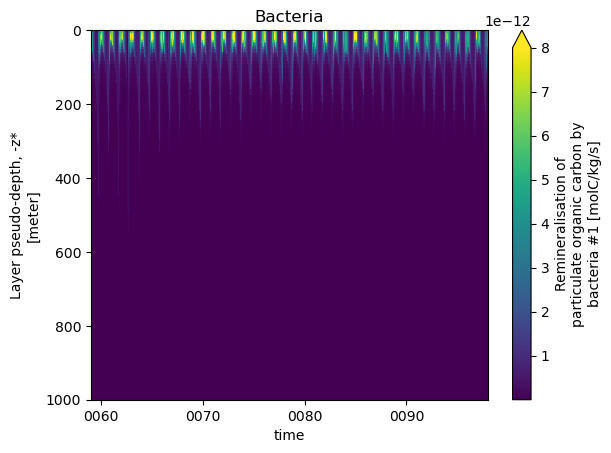

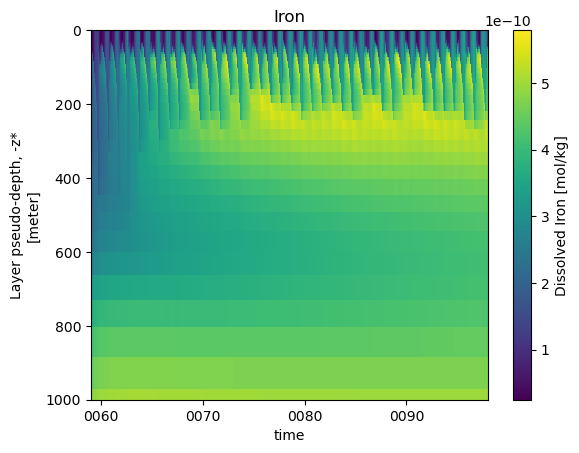

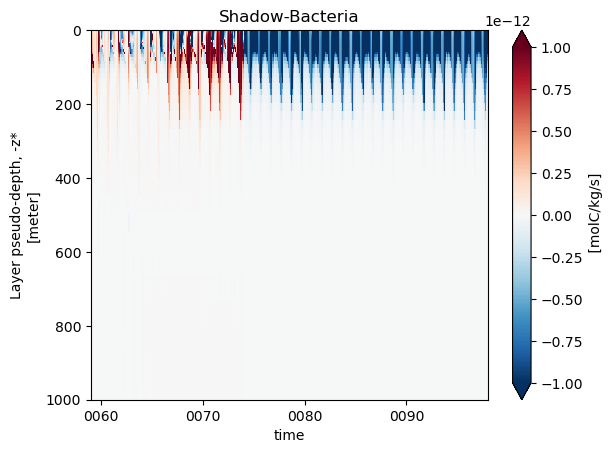

In [3]:
# first glimpse

ds_om3.sel(zl=np.arange(0,1000), method='nearest').poc1remi_nn.plot(x='time', ylim=(1000,0), vmax=8e-12)
plt.title('Shadow Emulator')
plt.show()

ds_om3.sel(zl=np.arange(0,1000), method='nearest').poc1remi.plot(x='time', ylim=(1000,0), vmax=8e-12)
plt.title('Bacteria')
plt.show()

ds_om3.sel(zl=np.arange(0,1000), method='nearest').fe.plot(x='time', ylim=(1000,0))
plt.title('Iron')
plt.show()


(ds_om3.sel(zl=np.arange(0,1000), method='nearest').poc1remi_nn -
 ds_om3.sel(zl=np.arange(0,1000), method='nearest').poc1remi).plot(x='time', ylim=(1000,0), vmax=1e-12)
plt.title('Shadow-Bacteria')
plt.show()

### can we recover **reminr** = poc1remi / det**2 * mmol_m3_to_mol_kg

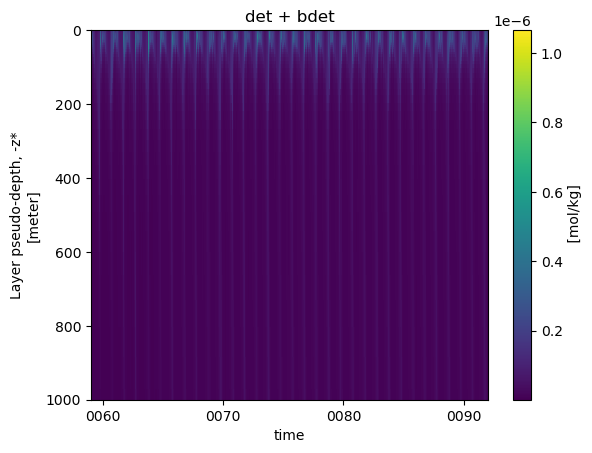

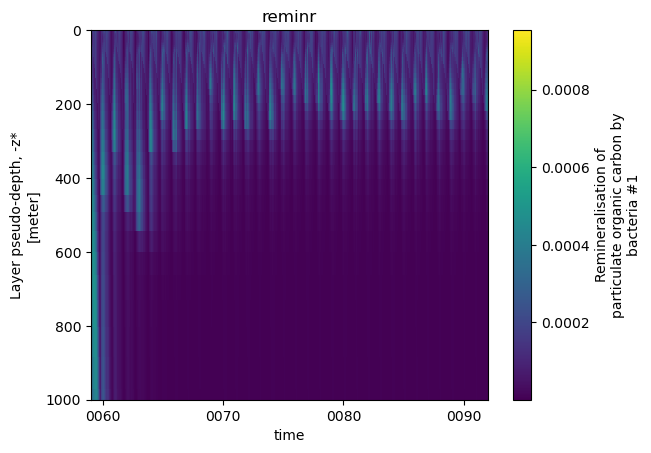

In [9]:
tot_det  = ds_om3.det + ds_om3.bdet
reminr = ds_om3.poc1remi / tot_det**2 * (1e-3/1035)

tot_det.plot(x='time', ylim=(1000,0))
plt.title('det + bdet')
plt.show()


reminr.plot(x='time', ylim=(1000,0))
plt.title('reminr')
plt.show()

thetao
phy
dia
zoo
mes
det
bdet
bac1
o2
fe
detremi
bdetremi
poc1remi
det_vmove


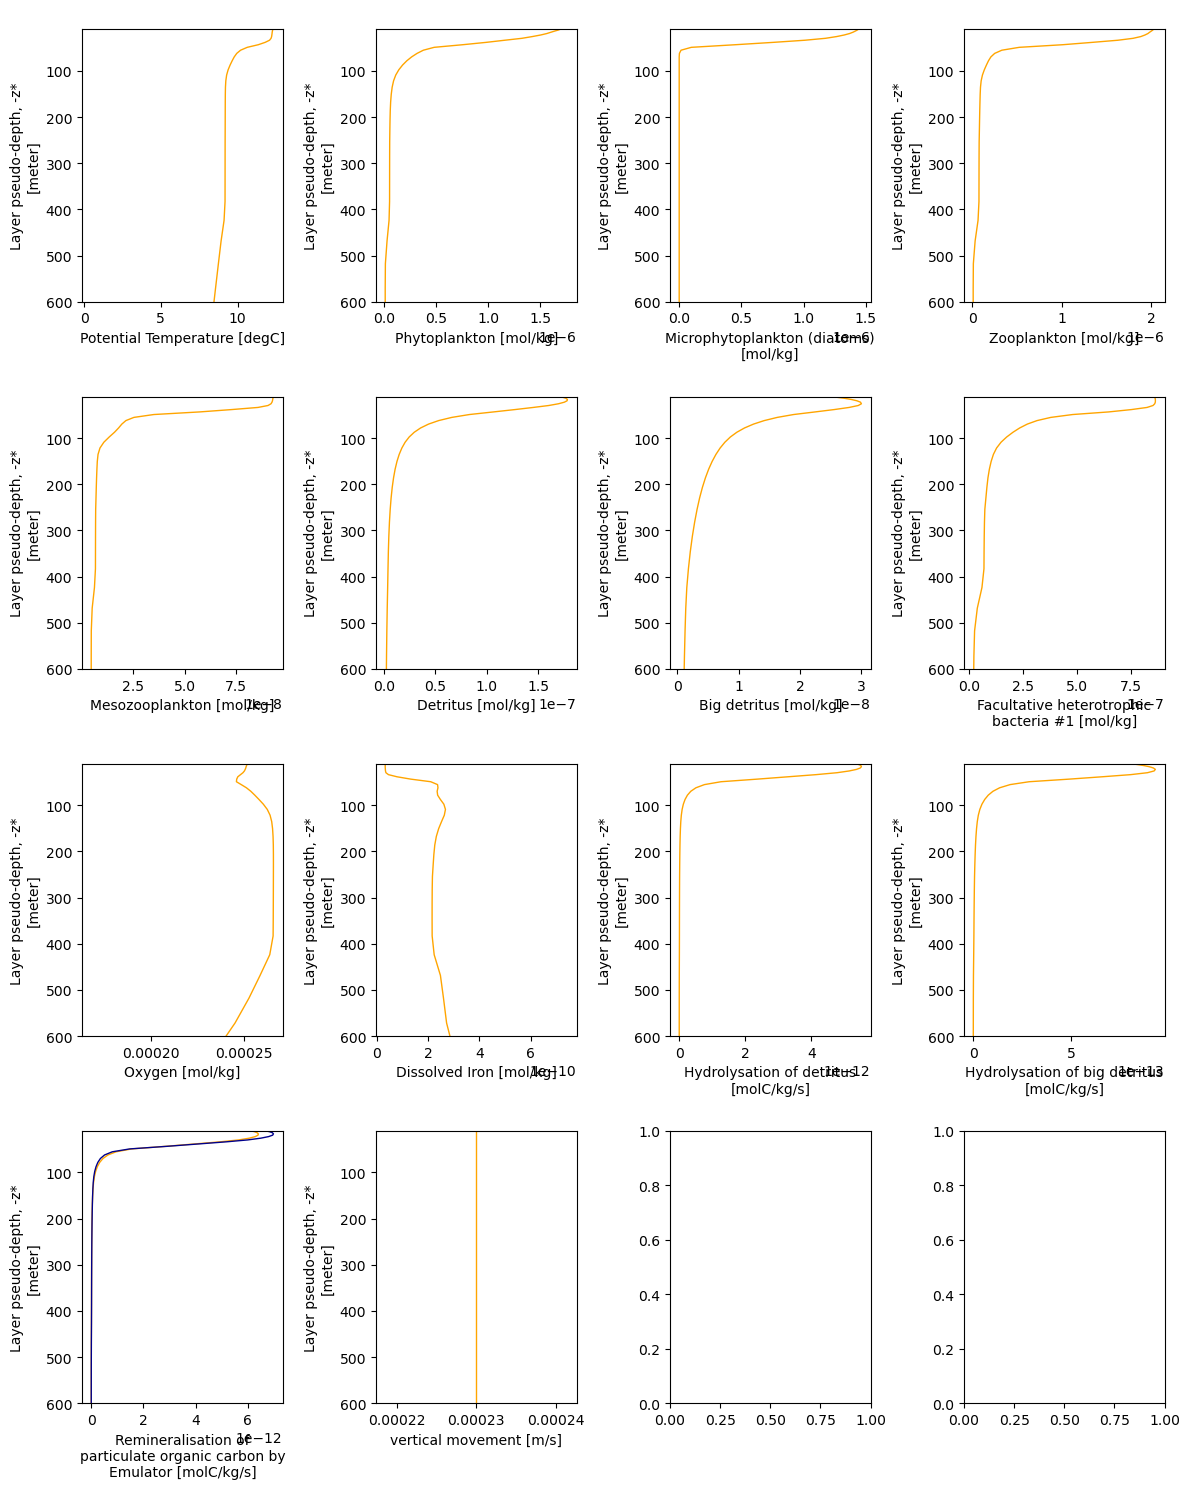

In [4]:
# check the different profiles

ds = ds_om3.groupby('time.year')[60].groupby('time.month')[2].mean(dim='time')
params = ['thetao',  'phy', 'dia' ,'zoo', 'mes','det', 'bdet', 'bac1', 'o2','fe','detremi','bdetremi','poc1remi','det_vmove']

fig, axes = plt.subplots(4,4, figsize=(12,15), sharey=False)
axes = axes.flatten()

for i, param in enumerate(params):
    print(param)
    ax=axes[i]
    ds[f'{param}'].plot(y='zl', ax = ax, linewidth=1, color='orange')
    ax.set_title(' ')
    ax.set_ylim(600,10)
ax=axes[-4]
ds['poc1remi_nn'].plot(y='zl', ax = ax, linewidth=1, color='darkblue')

plt.tight_layout()
plt.show()

In [4]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
 
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="All-NaN slice encountered")
 
#ORIG = "poc1remi"
#NN = "poc1remi_nn"
ORIG = "poc1remi"
NN = "poc1remi_nn"
 
 
def metrics(o, n):
    """Summary statistics for 1D arrays of original (o) and emulator (n) values."""
    o, n = np.asarray(o, float), np.asarray(n, float)
    out = {"N": o.size}
    if o.size == 0:
        return out
    d = n - o
    mean_o = o.mean()
    out["mean_orig"] = mean_o
    out["mean_nn"] = n.mean()
    out["bias"] = d.mean()
    out["rel_bias_%"] = 100 * d.mean() / mean_o if mean_o != 0 else np.nan
    out["MAE"] = np.abs(d).mean()
    out["RMSE"] = np.sqrt((d ** 2).mean())
    out["nRMSE_%"] = 100 * out["RMSE"] / mean_o if mean_o != 0 else np.nan
    sst = ((o - mean_o) ** 2).sum()
    out["R2"] = 1 - (d ** 2).sum() / sst if sst > 0 else np.nan
    out["corr"] = np.corrcoef(o, n)[0, 1] if (o.std() > 0 and n.std() > 0) else np.nan
    pos = (o > 0) & (n > 0)
    if pos.any():
        lr = np.log10(n[pos] / o[pos])
        out["median_log10_ratio"] = np.median(lr)
        out["within_x2_%"] = 100 * np.mean(np.abs(lr) < np.log10(2.0))
    return out
 
 
def roll(x, n=30):
    return pd.Series(x).rolling(n, center=True, min_periods=max(n // 2, 1)).mean().values
 

In [5]:
ds = ds_om3.sortby("time").isel(time=np.arange(365, len(ds_om3.time)))
zl = ds["zl"].values

A = ds[ORIG].squeeze().transpose("time", "zl")
B = ds[NN].squeeze().transpose("time", "zl")
units = A.attrs.get("units", "unknown")
a = A.values.astype(float)
b = B.values.astype(float)
nt, nz = a.shape

# valid = both finite and not a fill value
valid = np.isfinite(a) & np.isfinite(b) & (np.abs(a) < 1e10) & (np.abs(b) < 1e10)

# days since first record (falls back to the index if time arithmetic fails)
try:
    t0 = ds["time"].values[0]
    days = np.array([(t - t0).total_seconds() / 86400.0 for t in ds["time"].values])
except Exception:
    days = np.arange(nt, dtype=float)

# vertical weights: layer thickness 'h' if present, else spacing of zl (approximate)
if "h" in ds:
    w = ds["h"].squeeze().transpose("time", "zl").values.astype(float)
    w = np.where(np.isfinite(w), w, 0.0)
    wnote = "layer thickness h"
else:
    w = np.broadcast_to(np.gradient(zl), (nt, nz)).astype(float)
    wnote = "approximate spacing of zl (no 'h' variable found)"

print(f"Units (from file): {units}")
print(f"Vertical weights: {wnote}")
print(f"Time steps: {nt}   levels: {nz}   valid points: {int(valid.sum())} of {valid.size}")




Units (from file): molC/kg/s
Vertical weights: approximate spacing of zl (no 'h' variable found)
Time steps: 731   levels: 75   valid points: 54825 of 54825


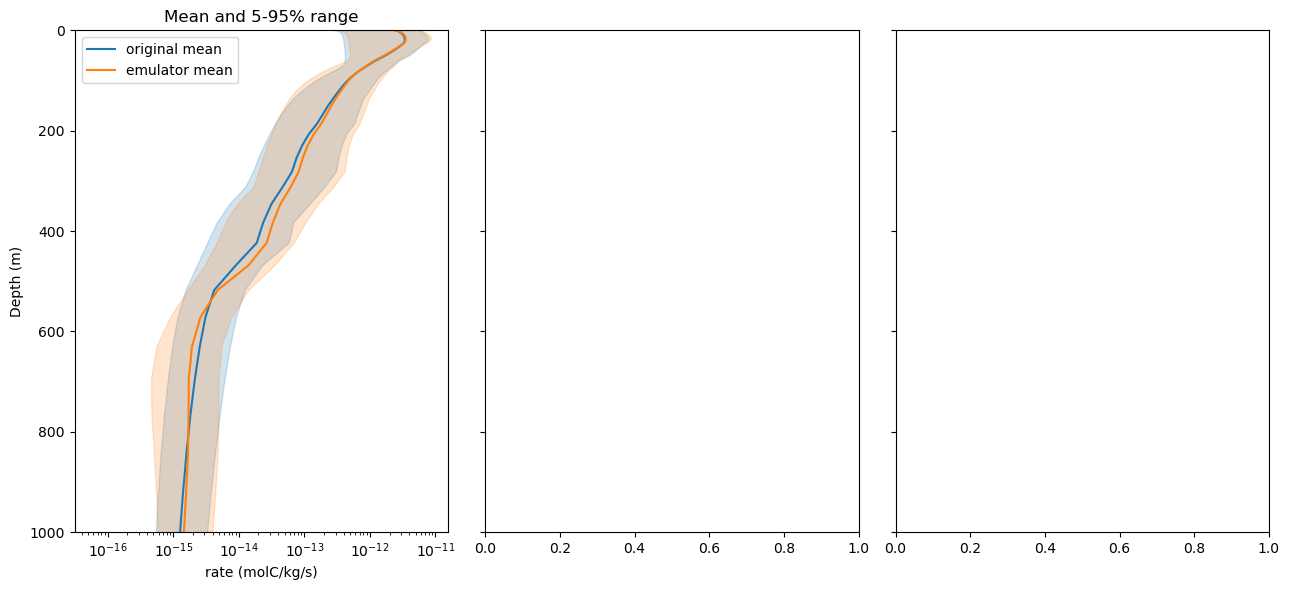

In [6]:

# %% CELL 7: figure 1, depth profiles
mo = np.where(valid, a, np.nan)
mn = np.where(valid, b, np.nan)
fig, ax = plt.subplots(1, 3, figsize=(13, 6), sharey=True)
for arr, lab, c in [(mo, "original", "C0"), (mn, "emulator", "C1")]:
    ax[0].plot(np.nanmean(arr, axis=0), zl, color=c, label=f"{lab} mean")
    ax[0].fill_betweenx(zl, np.nanpercentile(arr, 5, axis=0),
                        np.nanpercentile(arr, 95, axis=0), color=c, alpha=0.2)
ax[0].set_xscale("log")
ax[0].set_ylim(1000,0)
ax[0].set(xlabel=f"rate ({units})", ylabel="Depth (m)", title="Mean and 5-95% range")
ax[0].legend()

plt.tight_layout()
plt.show()



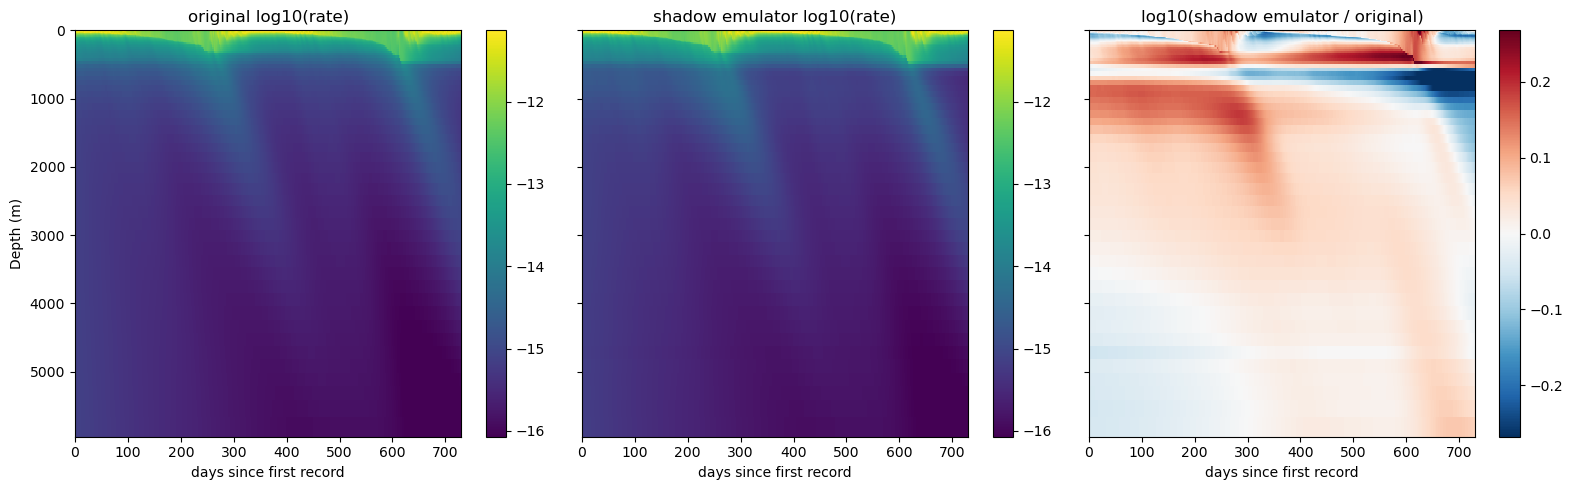

In [7]:

# %% CELL 9: figure 3, time-depth sections
with np.errstate(divide="ignore", invalid="ignore"):
    lo_ = np.where(valid & (a > 0), np.log10(a), np.nan)
    ln_ = np.where(valid & (b > 0), np.log10(b), np.nan)
both = np.concatenate([lo_[np.isfinite(lo_)], ln_[np.isfinite(ln_)]])
vmin, vmax = np.percentile(both, [1, 99]) if both.size else (None, None)
diff = ln_ - lo_
dmax = np.nanpercentile(np.abs(diff), 99) if np.isfinite(diff).any() else 1.0
fig, ax = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
panels = [(lo_, "original log10(rate)", dict(vmin=vmin, vmax=vmax, cmap="viridis")),
          (ln_, "shadow emulator log10(rate)", dict(vmin=vmin, vmax=vmax, cmap="viridis")),
          (diff, "log10(shadow emulator / original)", dict(vmin=-dmax, vmax=dmax, cmap="RdBu_r"))]
for axx, (arr, title, kw) in zip(ax, panels):
    mesh = axx.pcolormesh(days, zl, arr.T, shading="auto", **kw)
    axx.set(title=title, xlabel="days since first record")
    plt.colorbar(mesh, ax=axx)
ax[0].set_ylabel("Depth (m)")
ax[0].invert_yaxis()
plt.tight_layout()
plt.show()



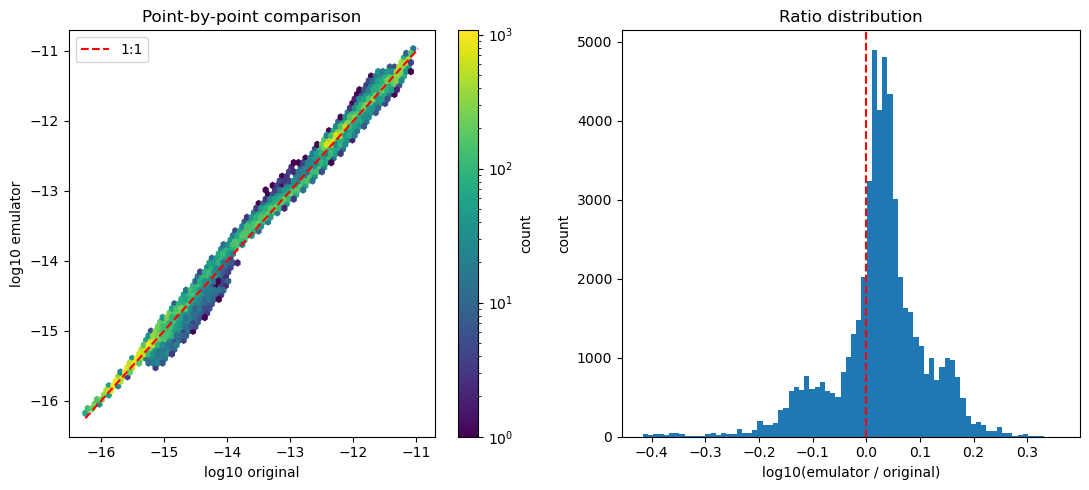

In [8]:

# %% CELL 10: figure 4, point-by-point comparison
pos = valid & (a > 0) & (b > 0)
la, lb = np.log10(a[pos]), np.log10(b[pos])
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
hb = ax[0].hexbin(la, lb, gridsize=70, bins="log")
lim = [min(la.min(), lb.min()), max(la.max(), lb.max())]
ax[0].plot(lim, lim, "r--", label="1:1")
ax[0].set(xlabel="log10 original", ylabel="log10 emulator", title="Point-by-point comparison")
ax[0].legend()
plt.colorbar(hb, ax=ax[0], label="count")
ax[1].hist(lb - la, bins=80)
ax[1].axvline(0, color="r", ls="--")
ax[1].set(xlabel="log10(emulator / original)", ylabel="count", title="Ratio distribution")
plt.tight_layout()
plt.show()

# Part 3: Evaluate Emulator Run

In [31]:
import xarray as xr
import pandas as pd
import glob
from dask import delayed, compute
import dask
import os
import matplotlib.pyplot as plt
import numpy as np

path_data =  '/../../../g/data/jk72/ao2582/PyTorch/emulator_data/mid_emulator_iaf_todz/output/'
#path_data = '/scratch/zn44/ao2582/access-om3/archive/mid_emulator_iaf_todz/output000/'
#path_data =  '/../../../g/data/jk72/ao2582/PyTorch/emulator_data/run_emulator_003/output/'
#path_data = '/scratch/zn44/ao2582/access-om3/archive/run_emulator_002/output003/'

files = glob.glob(path_data+ "*.nc")
#print(files)

params = ['thetao', 'mes', 'phy', 'zoo','det', 'dia', 'bdet', 'bac1','fe','o2', 'det_vmove', 'mlotst', 'detremi','bdetremi','poc1remi','poc1remi_nn']

# Load all variables and merge
ds_list = []
for var in params:
    try:
        ds_var = open_om3_variable(path_data, var)
        ds_list.append(ds_var)
        ds_var.close()
    except FileNotFoundError:
        print(f" Missing variable {var}")


# Merge variables
ds = xr.merge(ds_list, compat="override", join="override")
# Fix time encoding
ds = ds.assign_coords(time=ds.time)  # Ensure time is coordinate
ds.time.attrs["units"] = "days since 0001-01-01 00:00:00"
ds.time.attrs["calendar"] = "julian"
ds_em = xr.decode_cf(ds, decode_timedelta=False).compute().mean(dim=['xh','yh'])


    
print('-- done')

-- done


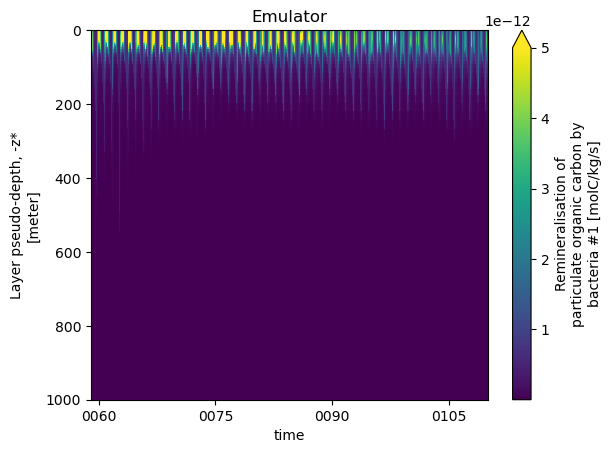

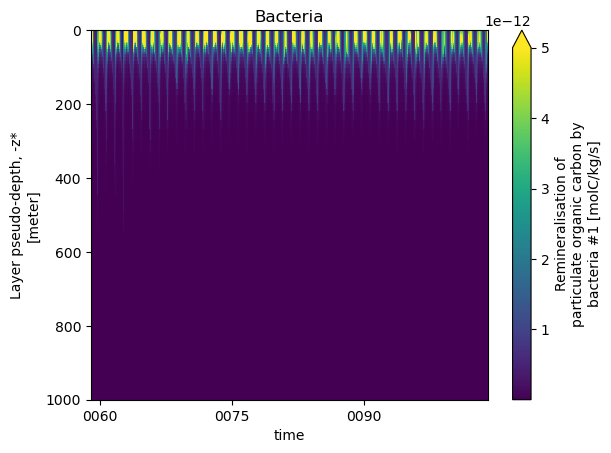

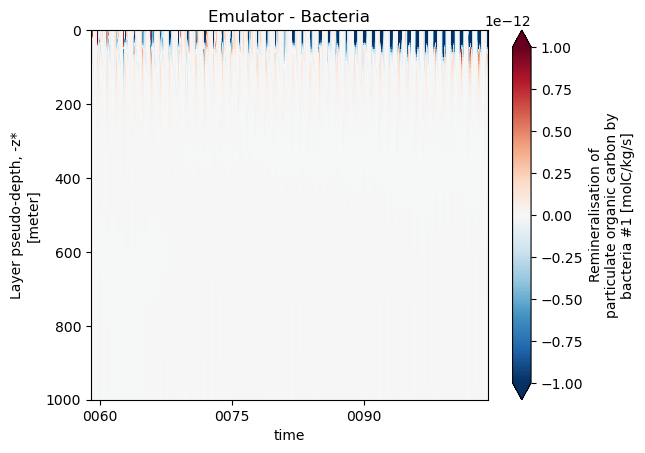

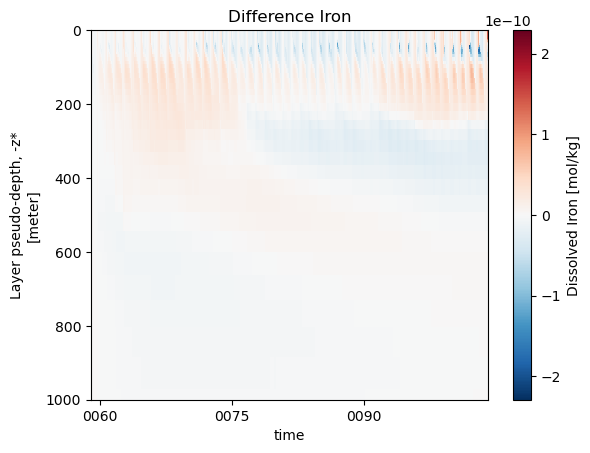

In [26]:
# first glimpse

ds_em.sel(zl=np.arange(0,1000), method='nearest').poc1remi.plot(x='time', ylim=(1000,0), vmax=5e-12)
plt.title('Emulator')
plt.show()
ds_om3.sel(zl=np.arange(0,1000), method='nearest').poc1remi.plot(x='time', ylim=(1000,0), vmax=5e-12)
plt.title('Bacteria')
plt.show()


(ds_em.sel(zl=np.arange(0,1000), method='nearest').poc1remi - ds_om3.sel(zl=np.arange(0,1000), method='nearest').poc1remi).plot(x='time', ylim=(1000,0), vmax=1e-12)
plt.title('Emulator - Bacteria')
plt.show()

(ds_em.sel(zl=np.arange(0,1000), method='nearest').fe - ds_om3.sel(zl=np.arange(0,1000), method='nearest').fe).plot(x='time', ylim=(1000,0))
plt.title('Difference Iron')
plt.show()


phy
dia
zoo
mes
det
bdet
bac1
o2
fe
detremi
bdetremi
poc1remi
det_vmove


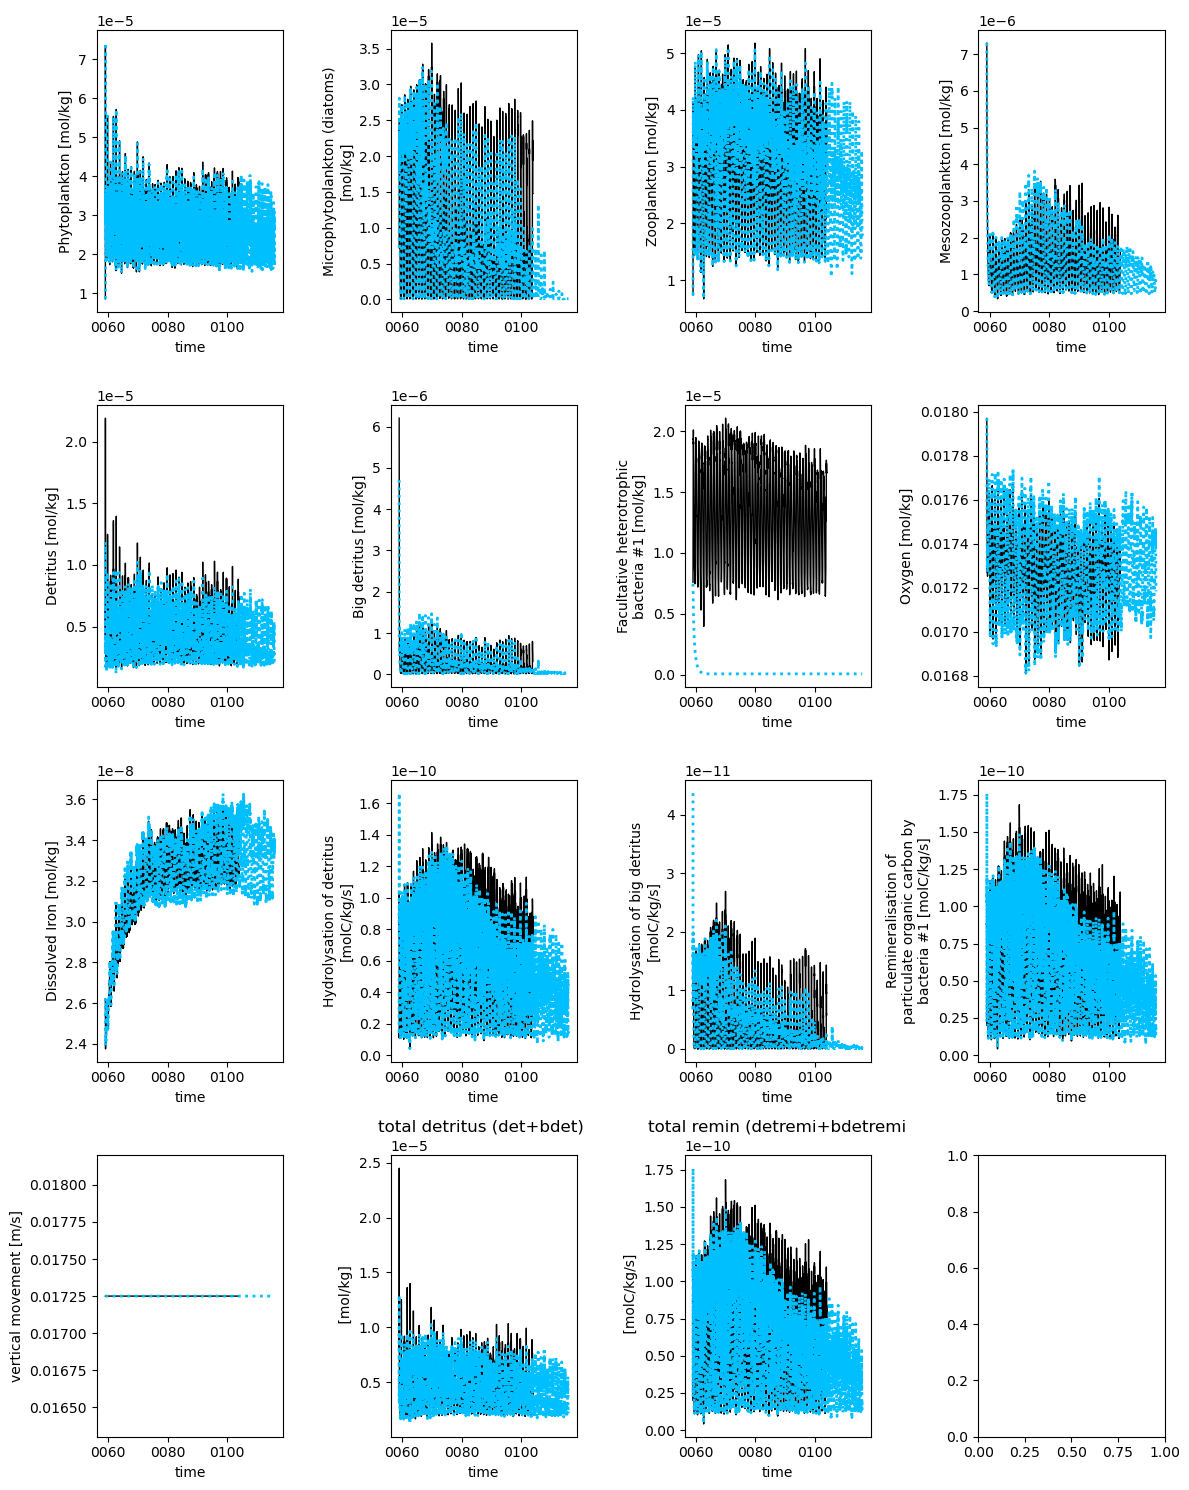

In [32]:
# check the different profiles
#ds_ogg = ds_om3.groupby('time.year')[3].groupby('time.month')[12].mean(dim='time')
#ds_emm = ds_em.groupby('time.year')[3].groupby('time.month')[12].mean(dim='time')
params = [ 'phy', 'dia' ,'zoo', 'mes','det', 'bdet', 'bac1', 'o2','fe','detremi','bdetremi','poc1remi','det_vmove']

fig, axes = plt.subplots(4,4, figsize=(12,15), sharey=False)
axes = axes.flatten()

for i, param in enumerate(params):
    print(param)
    ax=axes[i]
    ds_om3[f'{param}'].sum(dim='zl').plot(x='time', ax = ax, linewidth=1, color='black')
    ds_em[f'{param}'].sum(dim='zl').plot(x='time', ax = ax, linewidth=2, color='deepskyblue', linestyle='dotted')
    ax.set_title(' ')


ax=axes[-3]
#ds['poc1remi_nn'].plot(y='zl', ax = ax, linewidth=1, color='darkblue')
(ds_om3.det.sum(dim='zl') + ds_om3.bdet.sum(dim='zl')).plot(x='time', ax = ax, linewidth=1, color='black')
(ds_em.det.sum(dim='zl')+ds_em.bdet.sum(dim='zl')).plot(x='time', ax = ax, linewidth=2, color='deepskyblue', linestyle='dotted')
ax.set_title('total detritus (det+bdet) ')


ax=axes[-2]
#ds['poc1remi_nn'].plot(y='zl', ax = ax, linewidth=1, color='darkblue')
(ds_om3.detremi.sum(dim='zl') + ds_om3.bdetremi.sum(dim='zl')).plot(x='time', ax = ax, linewidth=1, color='black')
(ds_em.detremi.sum(dim='zl')+ds_em.bdetremi.sum(dim='zl')).plot(x='time', ax = ax, linewidth=2, color='deepskyblue', linestyle='dotted')
ax.set_title('total remin (detremi+bdetremi')

plt.tight_layout()
plt.show()

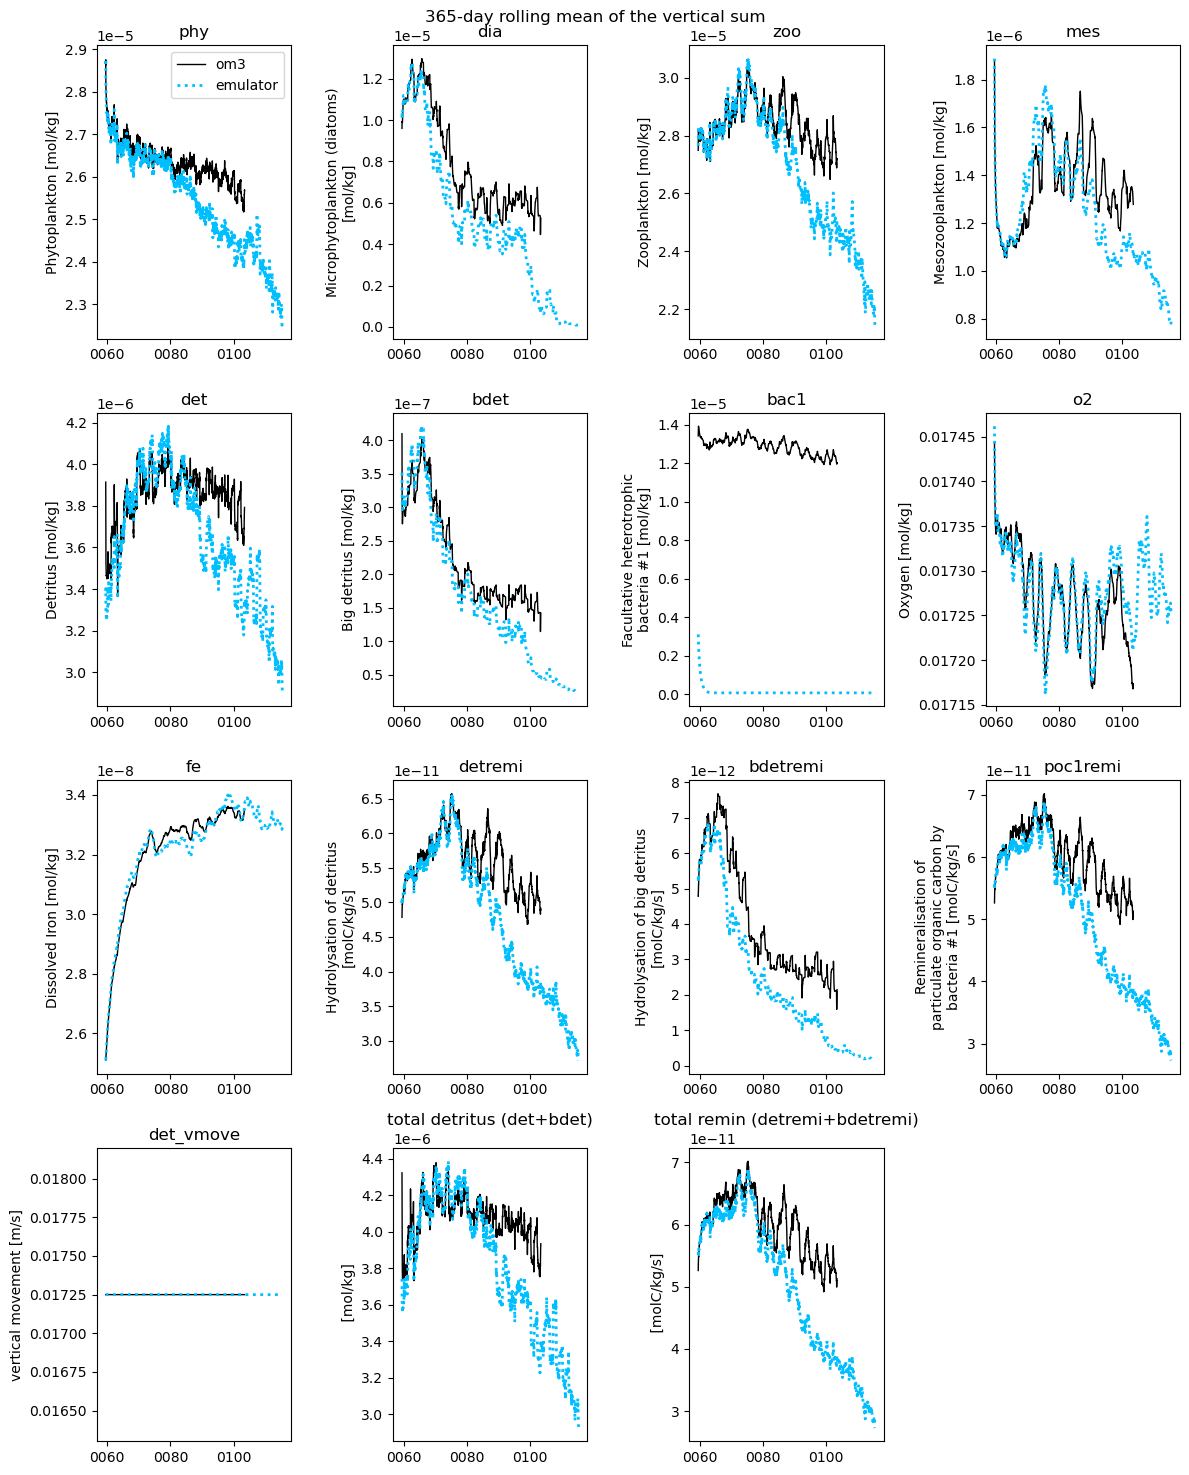

In [34]:
# Time series of the vertical sum, WOMBAT-mid original (om3) vs emulator, with a rolling mean
# over WINDOW records to remove the seasonal cycle. Notebook cell; nothing is saved.
# Needs: ds_om3, ds_em with dims (time, zl).
import matplotlib.pyplot as plt

WINDOW = 365  

params = ['phy', 'dia', 'zoo', 'mes', 'det', 'bdet', 'bac1', 'o2', 'fe',
          'detremi', 'bdetremi', 'poc1remi', 'det_vmove']


def smooth(da):
    """Sum over depth, then a centred rolling mean over WINDOW records.
    Values are NaN where the window is incomplete (about WINDOW/2 records at each end)."""
    return da.sum(dim='zl').rolling(time=WINDOW, center=True).mean()


def pair(ax, om3, em, title):
    om3.plot(x='time', ax=ax, linewidth=1, color='black', label='om3')
    em.plot(x='time', ax=ax, linewidth=2, color='deepskyblue', linestyle='dotted', label='emulator')
    ax.set_title(title)
    ax.set_xlabel('')


fig, axes = plt.subplots(4, 4, figsize=(12, 15), sharey=False)
axes = axes.flatten()

for ax, param in zip(axes, params):
    pair(ax, smooth(ds_om3[param]), smooth(ds_em[param]), param)

pair(axes[-3], smooth(ds_om3.det + ds_om3.bdet), smooth(ds_em.det + ds_em.bdet),
     'total detritus (det+bdet)')
pair(axes[-2], smooth(ds_om3.detremi + ds_om3.bdetremi), smooth(ds_em.detremi + ds_em.bdetremi),
     'total remin (detremi+bdetremi)')
axes[-1].set_visible(False)
axes[0].legend()

fig.suptitle(f'{WINDOW}-day rolling mean of the vertical sum')
plt.tight_layout()
plt.show()

16436 records (45.03 years); plots 1-2 use 15706 records after skipping 2 year(s)


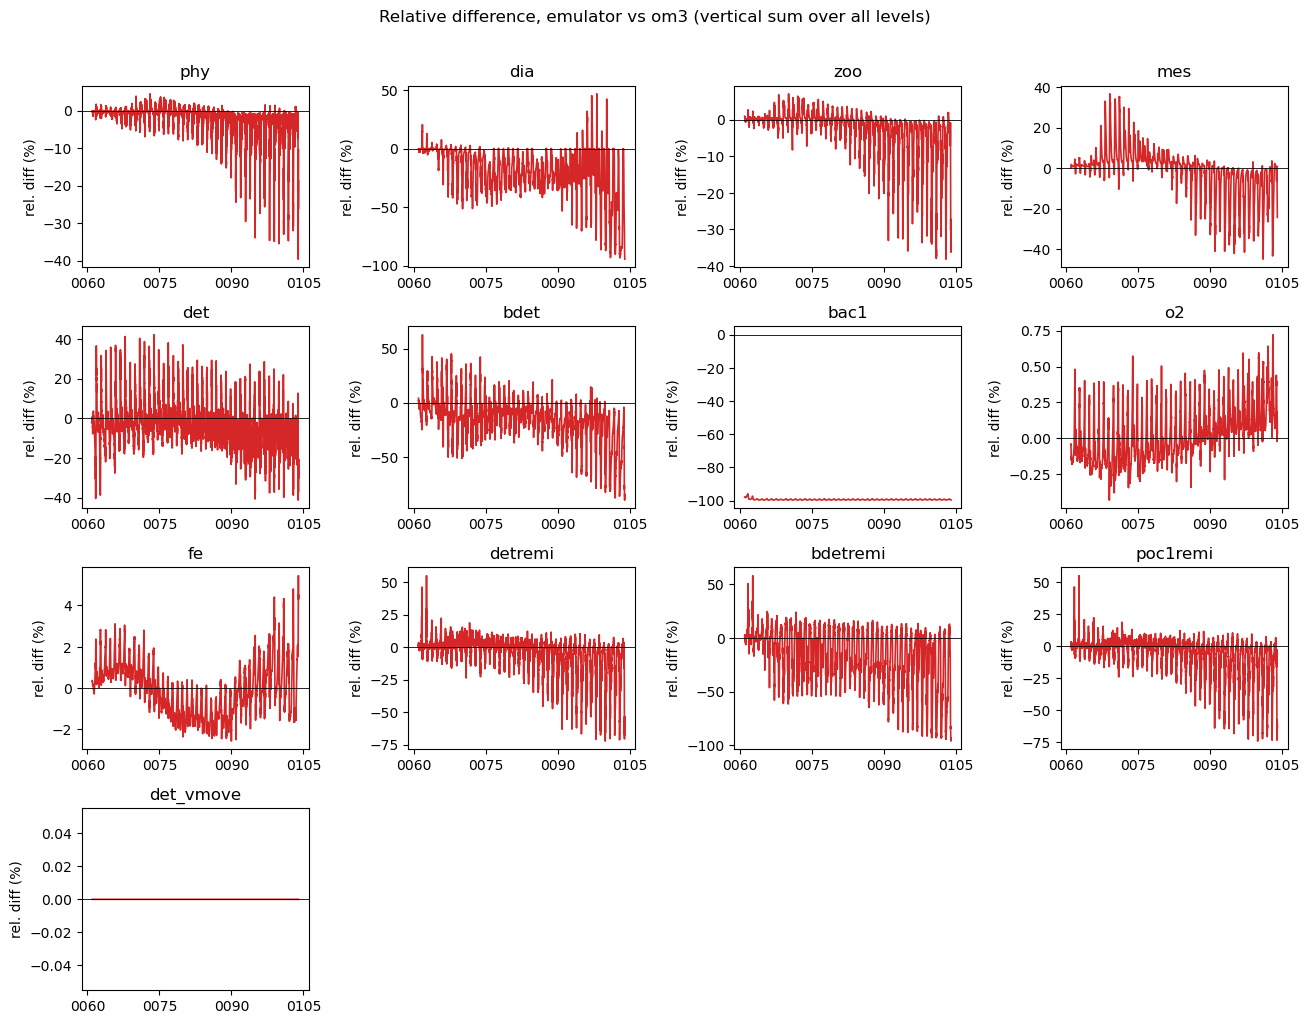

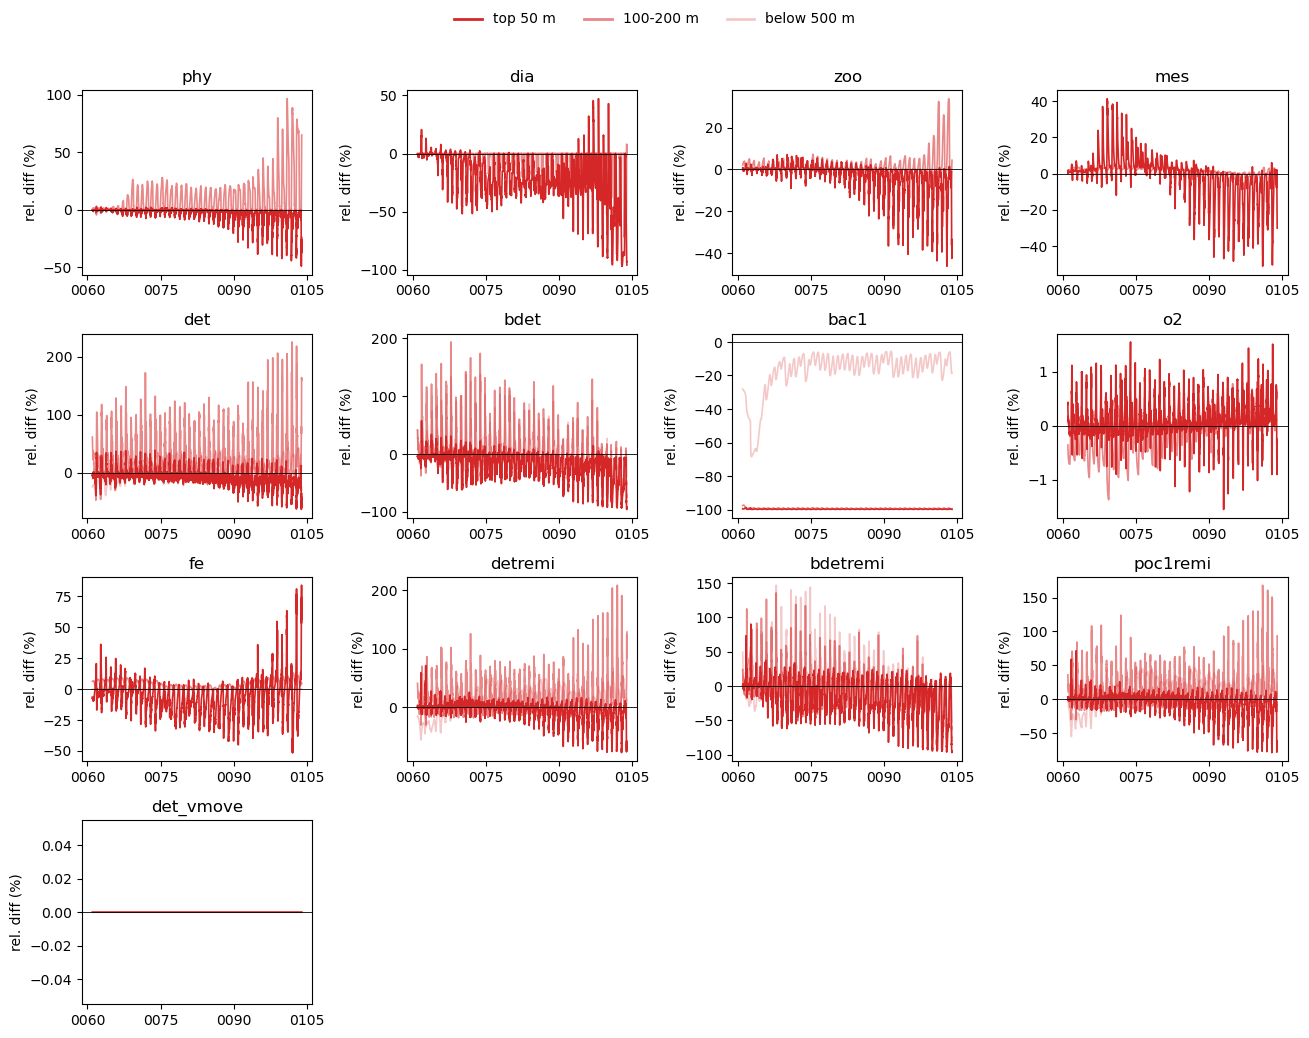

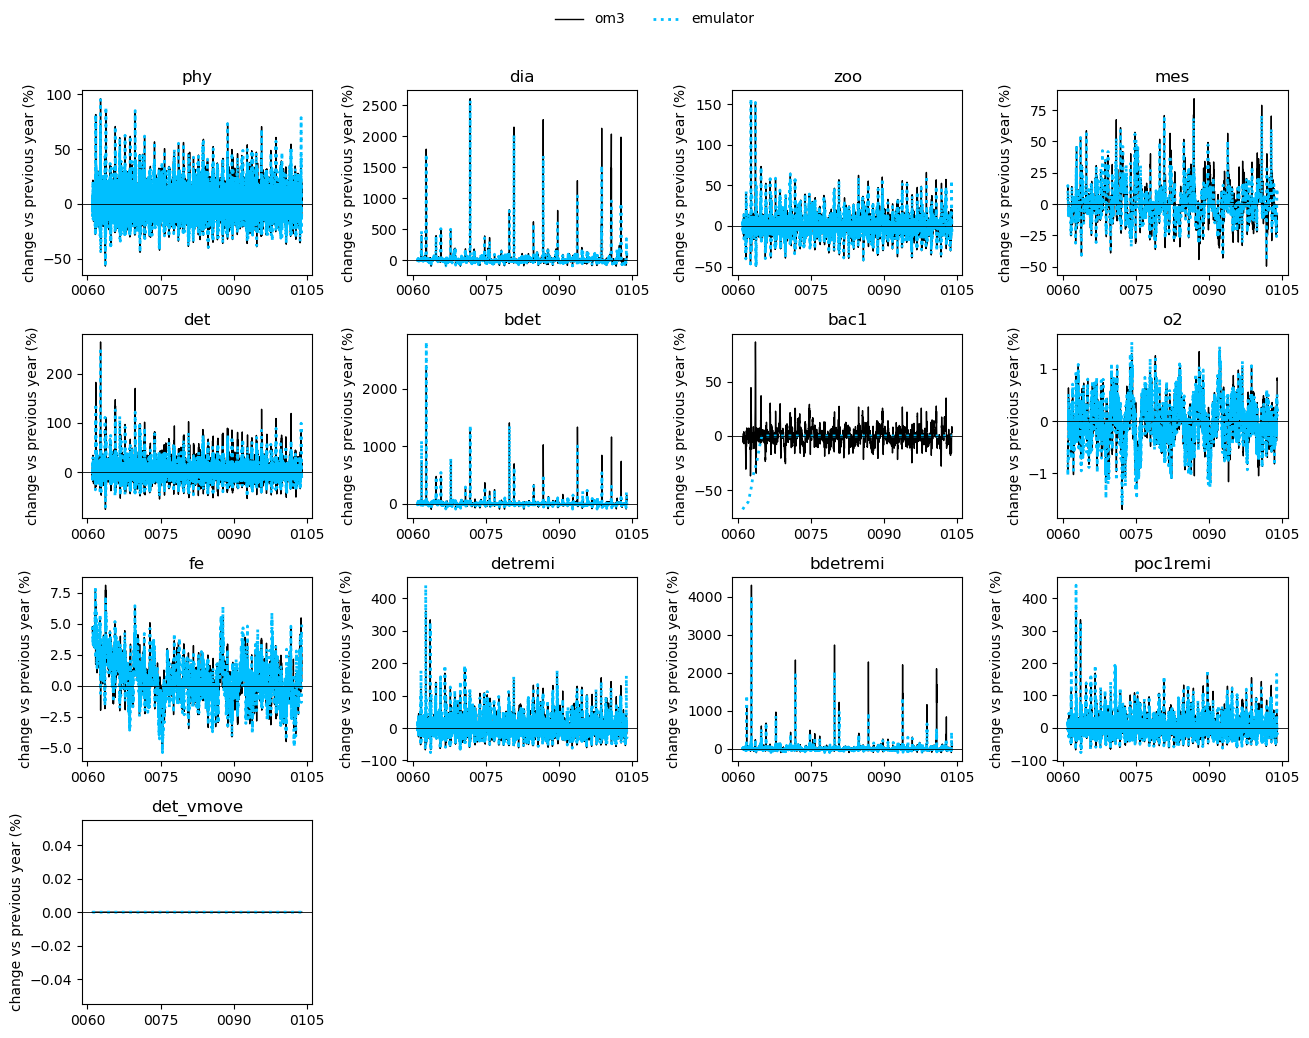

In [12]:
# Time-series comparison of the original run (ds_om3) and the emulator run (ds_em).
# Each "# %%" line starts a new notebook cell. Run top to bottom. Nothing is saved.
#
# Needs: ds_om3, ds_em  with dims (time, zl), the same variables as in your plots.
# Your ds_om3 / ds_em are never modified: the cells work on the copies
#   om3_full, em_full  (sorted, all years)   and   om3, em  (first SKIP_YEARS removed).
# So Cell 1 can be re-run safely.
# Convention: relative difference (%) = 100 * (emulator - om3) / om3.


# %% CELL 1: setup and helpers
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

PARAMS = ['phy', 'dia', 'zoo', 'mes', 'det', 'bdet', 'bac1', 'o2', 'fe',
          'detremi', 'bdetremi', 'poc1remi', 'det_vmove']

SKIP_YEARS = 2             # spin-up years left out of the plots (0 = keep everything)
AGG = "sum"                  # vertical aggregate: "sum" (as in your plots) or "mean"
SPY = 365                    # records per year (daily output, 365-day calendar)
BANDS = {"top 50 m": (None, 50), "100-200 m": (100, 200), "below 500 m": (500, None)}
ALPHAS = {"top 50 m": 1.0, "100-200 m": 0.55, "below 500 m": 0.25}   # same colour, different alpha

om3_full = ds_om3.sortby("time")
em_full = ds_em.sortby("time")
if not om3_full["time"].equals(em_full["time"]):
    if om3_full.sizes["time"] == em_full.sizes["time"]:
        print("WARNING: time stamps differ between the runs; matching records by position.")
        em_full = em_full.assign_coords(time=om3_full["time"])
    else:
        raise ValueError("ds_om3 and ds_em have different numbers of time records")

n_skip = SKIP_YEARS * SPY
if n_skip >= om3_full.sizes["time"]:
    raise ValueError(f"SKIP_YEARS={SKIP_YEARS} removes all {om3_full.sizes['time']} records")
om3 = om3_full.isel(time=slice(n_skip, None))
em = em_full.isel(time=slice(n_skip, None))
print(f"{om3_full.sizes['time']} records ({om3_full.sizes['time'] / SPY:.2f} years); "
      f"plots 1-2 use {om3.sizes['time']} records after skipping {SKIP_YEARS} year(s)")


def get(ds, name):
    """Variable with singleton dimensions removed."""
    return ds[name].squeeze(drop=True)


def vagg(da, lo=None, hi=None):
    """Aggregate over depth levels with lo <= zl <= hi (None = open end)."""
    da = da.sel(zl=slice(lo, hi))
    return da.sum("zl", min_count=1) if AGG == "sum" else da.mean("zl")


def reldiff(em_, om3_):
    """100 * (em - om3) / om3, NaN where om3 is exactly zero."""
    return 100 * (em_ - om3_) / om3_.where(om3_ != 0)


def panel_grid(n, ncols=4, w=3.3, h=2.6):
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(w * ncols, h * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.set_visible(False)
    return fig, axes


def has(p):
    return p in om3 and p in em


# %% CELL 2: plot 1 - relative difference between emulator and om3 (whole water column)
fig, axes = panel_grid(len(PARAMS))
for ax, p in zip(axes, PARAMS):
    if not has(p):
        ax.set_title(f"{p} (missing)")
        continue
    rd = reldiff(vagg(get(em, p)), vagg(get(om3, p)))
    rd.plot.line(x="time", ax=ax, color="C3", linewidth=1.2)
    ax.axhline(0, color="k", lw=0.6)
    ax.set(title=p, xlabel="", ylabel="rel. diff (%)")
fig.suptitle(f"Relative difference, emulator vs om3 (vertical {AGG} over all levels)")
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()


# %% CELL 3: plot 2 - relative difference by depth band (same colour, different alpha)
fig, axes = panel_grid(len(PARAMS))
for ax, p in zip(axes, PARAMS):
    if not has(p):
        ax.set_title(f"{p} (missing)")
        continue
    for name, (lo, hi) in BANDS.items():
        rd = reldiff(vagg(get(em, p), lo, hi), vagg(get(om3, p), lo, hi))
        rd.plot.line(x="time", ax=ax, color="C3", alpha=ALPHAS[name], linewidth=1.2)
    ax.axhline(0, color="k", lw=0.6)
    ax.set(title=p, xlabel="", ylabel="rel. diff (%)")
handles = [Line2D([0], [0], color="C3", alpha=ALPHAS[n], lw=2, label=n) for n in BANDS]
fig.legend(handles=handles, loc="upper center", ncol=len(BANDS), frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()


# %% CELL 4: plot 3 - change relative to the previous year (om3 and emulator)
RELATIVE = True              # True: % change vs previous year; False: absolute difference
YOY_BAND = (None, None)      # depth range (lo, hi) to aggregate over; (None, None) = all levels


def yoy(da):
    """value at t minus value one year (SPY records) earlier; NaN in the first year."""
    prev = da.shift(time=SPY)
    d = da - prev
    return 100 * d / prev.where(prev != 0) if RELATIVE else d


# The change is computed on ALL years and the skipped years are removed afterwards, so the
# first plotted year still has a previous year to compare with.
lo, hi = YOY_BAND
fig, axes = panel_grid(len(PARAMS))
for ax, p in zip(axes, PARAMS):
    if not (p in om3_full and p in em_full):
        ax.set_title(f"{p} (missing)")
        continue
    yo = yoy(vagg(get(om3_full, p), lo, hi)).isel(time=slice(n_skip, None))
    ye = yoy(vagg(get(em_full, p), lo, hi)).isel(time=slice(n_skip, None))
    yo.plot.line(x="time", ax=ax, color="black", linewidth=1)
    ye.plot.line(x="time", ax=ax, color="deepskyblue", linewidth=2, linestyle="dotted")
    ax.axhline(0, color="k", lw=0.6)
    ax.set(title=p, xlabel="", ylabel="change vs previous year" + (" (%)" if RELATIVE else ""))
fig.legend(handles=[Line2D([0], [0], color="black", lw=1, label="om3"),
                    Line2D([0], [0], color="deepskyblue", lw=2, ls=":", label="emulator")],
           loc="upper center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()